[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.2/Problem_2.21.ipynb)

# Chapter 2, Problem 21 — the hyperbolic world line

**Problem.** The world line of a particle is given parametrically, in some Lorentz frame, by
$$
t(\lambda) = a\sinh\frac{\lambda}{a},\qquad x(\lambda) = a\cosh\frac{\lambda}{a},
$$
where $\lambda$ is the parameter and $a$ a constant. Describe the motion and compute the four-velocity and acceleration components. Show that $\lambda$ is proper time along the world line and that the acceleration is uniform. Interpret $a$.

(Take $a > 0$; $y = z = 0$.)

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## The shape of the world line

Using $\cosh^2 - \sinh^2 = 1$:
$$
x^2 - t^2 = a^2\left(\cosh^2\frac\lambda a - \sinh^2\frac\lambda a\right) = a^2 .
$$
The world line is the right branch of the **invariant hyperbola** $x^2 - t^2 = a^2$ (Problem 1.3e): every event on it is at interval $+a^2$ from the origin.

**The motion.** Velocity $dx/dt = (dx/d\lambda)/(dt/d\lambda) = \sinh(\lambda/a)/\cosh(\lambda/a) = \tanh(\lambda/a) = t/x$.
- As $\lambda\to-\infty$ the particle comes in from $x = +\infty$ moving toward $-x$ at nearly light speed.
- It decelerates, comes momentarily to rest at $\lambda = 0$, $(t, x) = (0, a)$,
- then accelerates back out toward $+x$, approaching light speed as $t\to\infty$, asymptotic to the light ray $x = t$.

It stays forever outside the light cone of the origin ($x > |t|$). In fact no event with $t \geq x$ can ever send a signal that reaches the particle: the particle always stays ahead of any light ray emitted on or behind the line $t = x$. That line acts as a horizon for the accelerated observer (the "Rindler horizon").

## Four-velocity, and $\lambda$ is proper time

$$
\frac{d\vec x}{d\lambda} \to \left(\cosh\frac\lambda a,\ \sinh\frac\lambda a,\ 0,\ 0\right),
\qquad
\frac{d\vec x}{d\lambda}\cdot\frac{d\vec x}{d\lambda} = -\cosh^2 + \sinh^2 = -1 .
$$
A tangent vector of norm $-1$ means $d\tau^2 = -d\vec x\cdot d\vec x = d\lambda^2$, i.e. $d\tau = d\lambda$: **$\lambda$ is proper time** (up to an additive constant, here chosen so $\tau = 0$ at the turning point). Hence
$$
\boxed{\vec U = \frac{d\vec x}{d\tau} \to \left(\cosh\frac\tau a,\ \sinh\frac\tau a,\ 0,\ 0\right)}
$$

## Four-acceleration, and it's uniform

$$
\boxed{\vec a = \frac{d\vec U}{d\tau} \to \frac1a\left(\sinh\frac\tau a,\ \cosh\frac\tau a,\ 0,\ 0\right)},\qquad
\vec a\cdot\vec a = \frac{1}{a^2}\left(-\sinh^2 + \cosh^2\right) = \frac{1}{a^2}.
$$
- Constant magnitude: $\sqrt{\vec a\cdot\vec a} = 1/a$.
- Constant spatial direction: always along $x$ (no $y$, $z$ components).
- $\vec U\cdot\vec a = \frac1a(-\cosh\sinh + \sinh\cosh) = 0$ ✓.

So by Problem 19's definition the motion is **uniformly accelerated**, with proper acceleration $\alpha = 1/a$. In the MCRF, $\vec a \to (0, 1/a, 0, 0)$: an accelerometer aboard reads $1/a$ all the time.

## Interpreting $a$

- $\boxed{a = 1/\alpha}$ is the inverse of the proper acceleration: the larger $a$, the gentler the acceleration.
- $a$ is also the spatial distance, at the moment of rest, between the particle and the origin event: the hyperbola's vertex is at $x = a$. Every MCRF agrees: the particle's "now" line passes through the origin (it's the line $t/x = $ velocity, a radius of the hyperbola), and the proper distance along it to the particle is $\sqrt{x^2 - t^2} = a$.
- In ordinary units, $a = c^2/g_{\text{felt}}$. For 1 g, $a \approx 9\times10^{15}$ m ≈ 1 light-year (Problem 19).
- This is Problem 19's solution shifted in $x$ by $1/\alpha$ and with $t = 0$ chosen at the turning point instead of at the start from rest.

In [2]:
import sympy as sp
from schutz_gr import minkowski_dot
lam, a = sp.symbols("lambda a", positive=True)
X = sp.Matrix([a*sp.sinh(lam/a), a*sp.cosh(lam/a), 0, 0])
U = X.diff(lam); A = U.diff(lam)
print("x² − t² =", sp.simplify(X[1]**2 - X[0]**2))
print("U·U =", sp.simplify(minkowski_dot(U, U)), " ⇒ dτ = dλ")
print("a =", list(sp.simplify(A)), "  a·a =", sp.simplify(minkowski_dot(A, A)), "  U·a =", sp.simplify(minkowski_dot(U, A)))
print("velocity dx/dt =", sp.simplify(U[1]/U[0]))

x² − t² = a**2
U·U = -1  ⇒ dτ = dλ
a = [sinh(lambda/a)/a, cosh(lambda/a)/a, 0, 0]   a·a = a**(-2)   U·a = 0
velocity dx/dt = tanh(lambda/a)


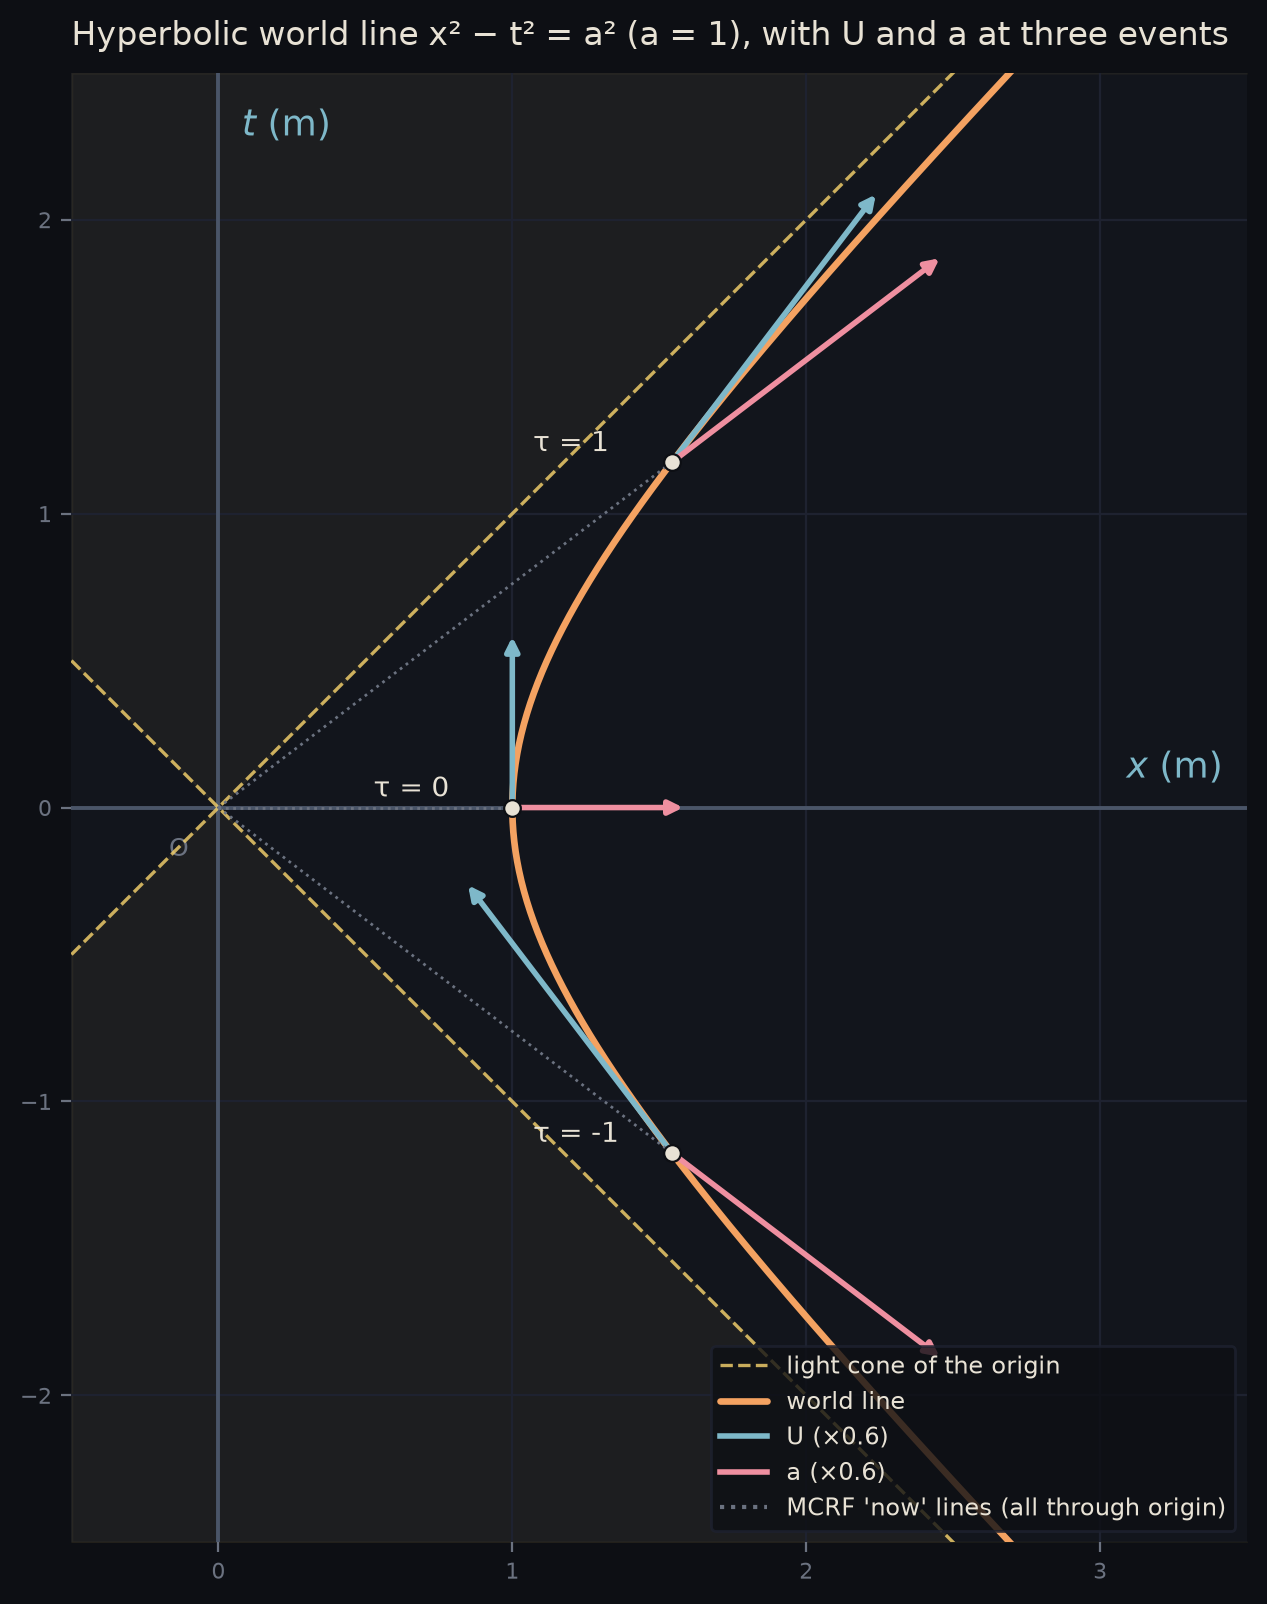

In [3]:
import numpy as np
from schutz_gr.diagrams import SpacetimeDiagram, COLORS
%config InlineBackend.figure_format = 'retina'
aa = 1.0
d = SpacetimeDiagram(xlim=(-0.5, 3.5), tlim=(-2.5, 2.5), title="Hyperbolic world line x² − t² = a² (a = 1), with U and a at three events", size=6.5)
d.light_cone(label="light cone of the origin", color="gold")
L = np.linspace(-2.2, 2.2, 400)
d.line(aa*np.cosh(L/aa), aa*np.sinh(L/aa), color="amber", lw=2.4, label="world line")
for l0 in (-1.0, 0.0, 1.0):
    tt, xx = aa*np.sinh(l0/aa), aa*np.cosh(l0/aa)
    U = np.array([np.cosh(l0/aa), np.sinh(l0/aa)]) * 0.6
    Ac = np.array([np.sinh(l0/aa), np.cosh(l0/aa)]) / aa * 0.6
    d.ax.annotate("", xy=(xx + U[1], tt + U[0]), xytext=(xx, tt), arrowprops=dict(arrowstyle="-|>", color=COLORS["teal"], lw=2))
    d.ax.annotate("", xy=(xx + Ac[1], tt + Ac[0]), xytext=(xx, tt), arrowprops=dict(arrowstyle="-|>", color=COLORS["rose"], lw=2))
    d.line([0, xx], [0, tt], color="grey", ls=":", lw=1)
    d.event(tt, xx, name=f"τ = {l0:g}", offset=(-50, 4))
d.ax.plot([], [], color=COLORS["teal"], lw=2, label="U (×0.6)"); d._legend_handles.append(d.ax.lines[-1])
d.ax.plot([], [], color=COLORS["rose"], lw=2, label="a (×0.6)"); d._legend_handles.append(d.ax.lines[-1])
d.ax.plot([], [], color=COLORS["grey"], ls=":", label="MCRF 'now' lines (all through origin)"); d._legend_handles.append(d.ax.lines[-1])
d.show(loc="lower right")